# Extended Data Fig. 2: spatial enrichment fidelity in mouse brain

Mouse brain Visium (2,688 spots), top-10 signatures of the pyramidal layer and the striatum. EnrichMap (null) and
EnrichMap (smoothing) are compared with AUCell, GSVA, ssGSEA, Z score and Scanpy (as in `01_visium_platform`) and GSDensity
(relevance from `data/gsd_cache/brain`). Panels: a score maps, b Moran's I and Geary's C, c variograms, d
region-vs-rest classification, e Moran scatter of EnrichMap (null), f PCA of gene contributions. In b-d, filled markers are the
pyramidal layer and open markers the striatum.

In [1]:
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

In [2]:
import scanpy as sc
import pandas as pd
import numpy as np
import gseapy as gp
import decoupler as dc
import enrichmap as em
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from adjustText import adjust_text
from esda.moran import Moran
from libpysal.weights import KNN
from matplotlib.lines import Line2D
from scipy.sparse import issparse
from scipy.spatial.distance import pdist
from skgstat import Variogram
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score, roc_auc_score

from helpers import (
    _benchmark_pooled,
    _optimal_f1,
    spatial_knn_connectivity,
    ring_distance_to_region,
    ring_leakage_profile,
    f1_of_calls,
    f1_median_threshold,
    f1_prevalence_top_k,
    otsu_threshold_1d,
    f1_otsu_threshold,
    spatial_block_partition,
    f1_spatial_block_cv,
    threshold_rule_metrics,
    null_model_rule_calls,
    paired_block_bootstrap_rules,
    percentile_interval,
    median_threshold_f1_ceiling,
    format_estimate_ci,
    moran_scatter_quadrants,
    plot_spatial_metric_bars,
    plot_metric_pair_by_method,
    plot_benchmark_dot_summary,
    plot_estimate_ci,
    format_benchmark_metric_axis,
    plot_fixed_rule_f1,
)

In [3]:
sc.set_figure_params(frameon=False, fontsize=6)
sc.settings._vector_friendly = False

In [4]:
# set working directory
# repository root (the folder containing `notebooks/`); safe to re-run this cell
import sys
project_dir = os.getcwd()
if os.path.basename(project_dir) == "notebooks":
    project_dir = os.path.dirname(project_dir)
project_dir += "/"
sys.path.insert(0, project_dir + "notebooks")  # helpers.py and score_signatures.py
working_dir = project_dir
os.chdir(working_dir)

# set figure directory
figure_dir = working_dir + "figures/"
os.makedirs(figure_dir, exist_ok=True)
sc.settings.figdir = figure_dir

# processed data directory
processed_data = working_dir + "processed_data/"


# source data directory
source_dir = working_dir + "source_data/"
os.makedirs(source_dir, exist_ok=True)

In [5]:
colours = {
    "EnrichMap (null)": "#2f0bdf",
    "EnrichMap (smoothing-only)": "#a393f8",
    "AUCell": "#86bf6e",
    "GSVA": "#c76663",
    "ssGSEA": "#8f6eb0",
    "Z score": "#866342",
    "Scanpy": "#cf83bd",
    "GSDensity": "#e3a33b",
}
spot_size = 20

In [6]:
# 1. Load data, signatures and region labels
adata = sc.read_h5ad(processed_data + "visium_brain_adata.h5ad")

cell_type_1 = "Pyramidal_layer"
cell_type_2 = "Striatum"
regions = [cell_type_1, cell_type_2]
region_labels = {cell_type_1: "Pyramidal layer", cell_type_2: "Striatum"}

with open(f"{cell_type_1}_signatures.pkl", "rb") as f:
    signature_dict_pyramidal = pickle.load(f)
with open(f"{cell_type_2}_signatures.pkl", "rb") as f:
    signature_dict_striatum = pickle.load(f)

signatures_dict = {
    cell_type_1: list(signature_dict_pyramidal[f"{cell_type_1}_top10"]),
    cell_type_2: list(signature_dict_striatum[f"{cell_type_2}_top10"]),
}

coords = np.asarray(adata.obsm["spatial"], dtype=np.float64)
labels = {ct: (adata.obs["cluster"] == ct).values.astype(int) for ct in regions}

print(adata.shape)
for ct in regions:
    print(f"{ct}: {labels[ct].sum()}/{adata.n_obs} spots | {', '.join(signatures_dict[ct])}")

(2688, 18078)
Pyramidal_layer: 42/2688 spots | Lefty1, 6330420H09Rik, B230110G15Rik, Fgf16, Fibcd1, 4921539H07Rik, Spink8, Efcab6, Tmprss6, Gm2115
Striatum: 153/2688 spots | Ucn3, Cyp19a1, Adora2a, Ccdc42, Ido1, Sstr5, Chrna10, Gm48485, 6430628N08Rik, Penk


In [7]:
# 2. EnrichMap: null model (default) and smoothing-only
variants = {
    "null": dict(null_model=True, correct_spatial_covariates=False, compute_q_vals=True),
    "smooth": dict(null_model=False, correct_spatial_covariates=False),
}

for ct, genes in signatures_dict.items():
    for name, kwargs in variants.items():
        em.tl.score(adata, gene_set=genes, score_key=f"{ct}_{name}", n_neighbors=6, smoothing=True, **kwargs)

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring Pyramidal_layer_null: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring Pyramidal_layer_null: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 10.23it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring Pyramidal_layer_smooth: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring Pyramidal_layer_smooth: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 10.39it/s]

... (3 outputs left out)

Scoring Striatum_null: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00,  9.71it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring Striatum_smooth: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring Striatum_smooth: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 10.47it/s]

In [8]:
# 3. Comparators as in 01_visium_platform: AUCell, GSVA, ssGSEA, Z score and Scanpy
X_dense = adata.X.toarray() if issparse(adata.X) else adata.X.copy()
gene_expr = pd.DataFrame(X_dense.T, index=adata.var_names, columns=adata.obs_names)
gene_expr_upper = gene_expr.copy()
gene_expr_upper.index = gene_expr_upper.index.str.upper()
signatures_dict_upper = {k: [g.upper() for g in v] for k, v in signatures_dict.items()}

# AUCell, both signatures in one network
signatures_dc = pd.DataFrame(
    [(key, gene) for key, genes in signatures_dict.items() for gene in genes],
    columns=["source", "target"],
)
dc.mt.aucell(adata, net=signatures_dc)
score_aucell = dc.pp.get_obsm(adata=adata, key="score_aucell").obsm["score_aucell"]
for ct in regions:
    adata.obs[f"{ct}_aucell_score"] = score_aucell[ct].values

# GSVA
gsva = gp.gsva(data=gene_expr, gene_sets=signatures_dict, outdir=None, min_size=5)
es = gsva.res2d.pivot(index="Term", columns="Name", values="ES")
for ct in regions:
    adata.obs[f"{ct}_gsva_score"] = es.loc[ct].T.astype(float).reindex(adata.obs_names).values

# ssGSEA
ssgsea = gp.ssgsea(
    data=gene_expr_upper,
    gene_sets=signatures_dict_upper,
    outdir=None,
    sample_norm_method="rank",
    no_plot=True,
    min_size=5,
)
nes = ssgsea.res2d.pivot(index="Term", columns="Name", values="NES")
for ct in regions:
    adata.obs[f"{ct}_ssgsea_score"] = nes.loc[ct].T.astype(float).reindex(adata.obs_names).values

# Z score and Scanpy
for ct in regions:
    gene_set = signatures_dict_upper[ct]
    adata.obs[f"{ct}_z_score"] = (gene_expr_upper.loc[gene_set].sum(axis=0) / np.sqrt(len(gene_set))).values
    sc.tl.score_genes(adata, signatures_dict[ct], score_name=f"{ct}_scanpy_score", layer="log1p_norm")
del X_dense, gene_expr, gene_expr_upper

In [9]:
# 4. GSDensity relevance (R4_F1_GSDensity run), and the score of every method
for ct in regions:
    gsd = pd.read_csv(working_dir + f"data/gsd_cache/brain/{ct}.csv", index_col=0).reindex(adata.obs_names)
    adata.obs[f"{ct}_gsdensity_score"] = gsd["relevance"].values

# score column of each method
method_keys = {
    "EnrichMap (null)": "{ct}_null_score",
    "EnrichMap (smoothing-only)": "{ct}_smooth_score",
    "AUCell": "{ct}_aucell_score",
    "GSVA": "{ct}_gsva_score",
    "ssGSEA": "{ct}_ssgsea_score",
    "Z score": "{ct}_z_score",
    "Scanpy": "{ct}_scanpy_score",
    "GSDensity": "{ct}_gsdensity_score",
}
NULL, SMOOTH = "EnrichMap (null)", "EnrichMap (smoothing-only)"
METHODS = list(method_keys)

scores = {
    ct: {m: adata.obs[k.format(ct=ct)].values.astype(np.float64) for m, k in method_keys.items()}
    for ct in regions
}
p_empirical = {ct: np.asarray(adata.uns["null_model"][f"{ct}_null"]["p_empirical"], dtype=np.float64) for ct in regions}

summary_rows = []
for ct in regions:
    for m in [NULL, SMOOTH]:
        s = scores[ct][m]
        summary_rows.append({
            "region": region_labels[ct], "variant": m, "min": s.min(), "median": np.median(s),
            "max": s.max(), "mean": s.mean(), "SD": s.std(),
        })
print(pd.DataFrame(summary_rows).round(4).to_string(index=False))

         region                    variant     min  median     max    mean     SD
Pyramidal layer           EnrichMap (null) -2.7403 -1.1035 27.0046 -0.0703 3.7190
Pyramidal layer EnrichMap (smoothing-only)  0.0000  0.0084  0.2846  0.0191 0.0377
       Striatum           EnrichMap (null) -2.8934 -0.9913 21.3246 -0.0028 3.1520
       Striatum EnrichMap (smoothing-only)  0.0000  0.0071  0.2104  0.0147 0.0254


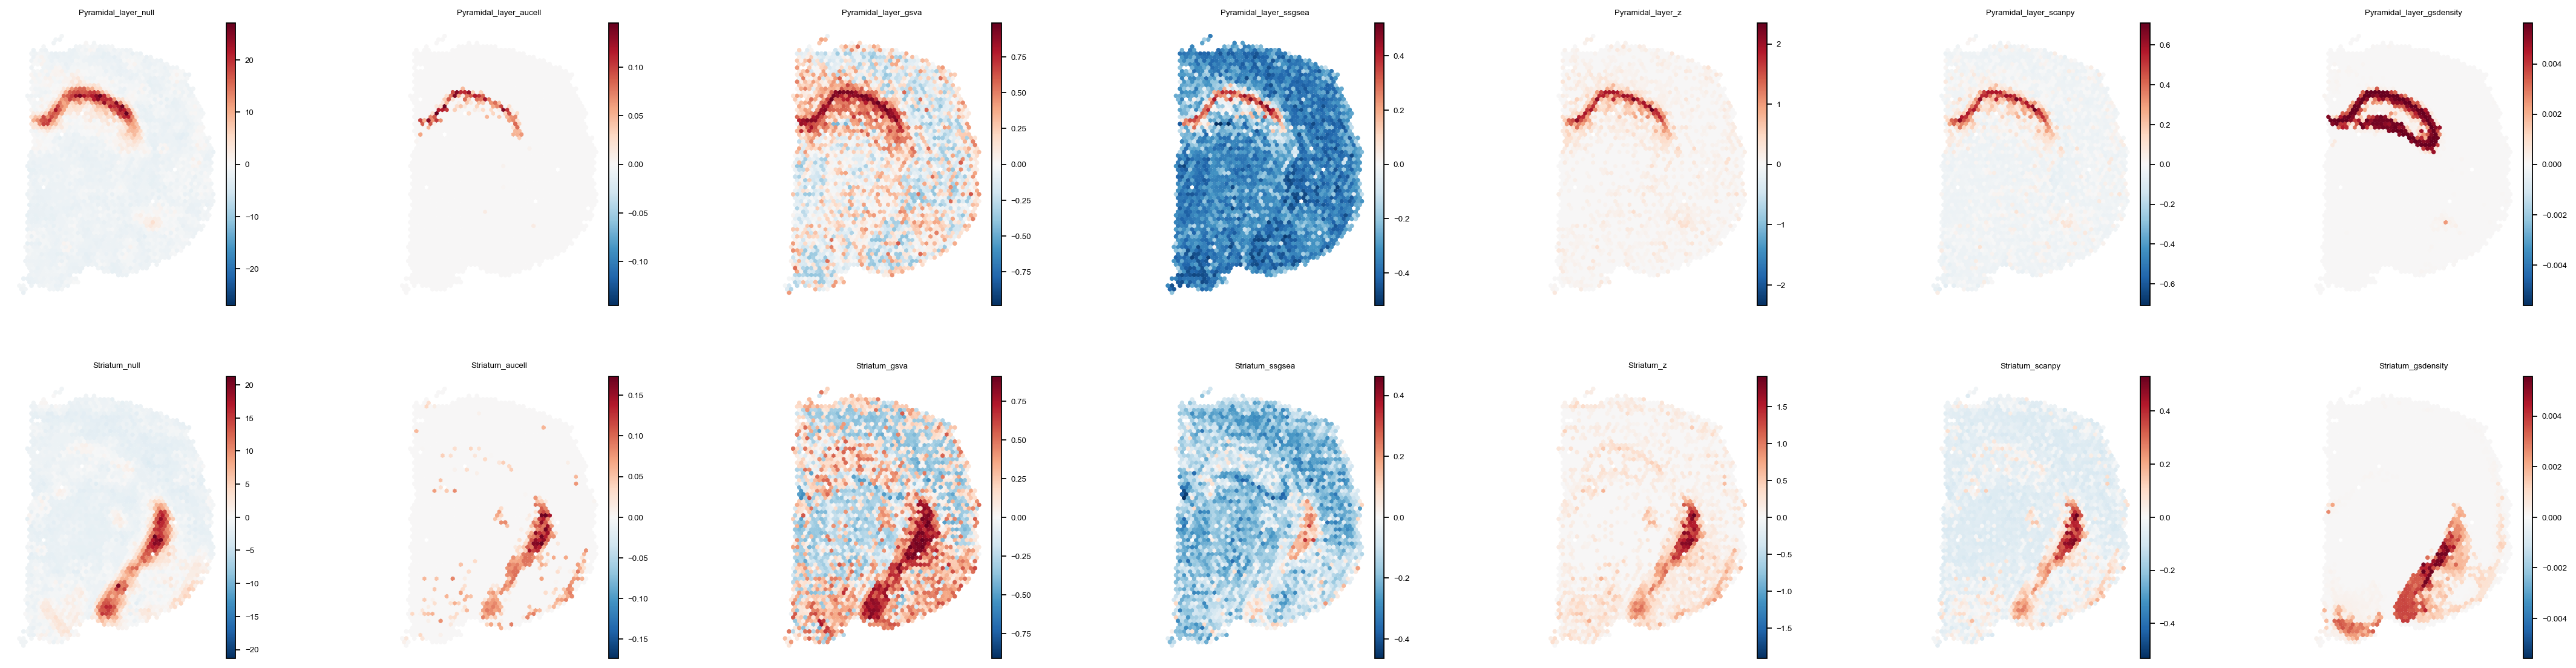

In [10]:
# 6. Extended Data Fig. 2a: score maps of EnrichMap (null), the comparators and GSDensity, centred at 0
methods_a = [m for m in METHODS if m != SMOOTH]
map_keys = [method_keys[m].format(ct=ct) for ct in regions for m in methods_a]
em.pl.spatial_enrichmap(
    adata,
    score_key=map_keys,
    shape=None,
    vcenter=0,
    size=spot_size,
    ncols=len(methods_a),
    save="ExtendedDataFig2a_score_maps.pdf",
)

maps = pd.DataFrame({
    "spot_id": adata.obs_names,
    "x": coords[:, 0],
    "y": coords[:, 1],
    "cluster": adata.obs["cluster"].astype(str).values,
})
for ct in regions:
    for m in methods_a:
        maps[f"{region_labels[ct]} | {m}"] = scores[ct][m]
maps.to_csv(source_dir + "ExtendedDataFig2a_score_maps.csv", index=False)

In [11]:
# # 7. Halo around each region (rings of the 6-NN graph): L(d) = (ring mean - far background) / (region - far background)
conn = spatial_knn_connectivity(coords, n_neighbors=6)

In [12]:
# 8. Sup. Fig. 2b-c: Moran's I and Geary's C (em.tl.compute_spatial_metrics, as em.pl.spatial_metrics in 01_visium_platform)
W6 = KNN.from_array(coords, k=6)
W6.transform = "r"

summary_rows = []
for ct in regions:
    for m, k in method_keys.items():
        metrics, _ = em.tl.compute_spatial_metrics(adata, score_key=k.format(ct=ct), n_neighbors=6)
        summary_rows.append({
            "region": region_labels[ct], "method": m, "Moran's I": metrics["Moran's I"],
            "Geary's C": metrics["Geary's C"],
            "Moran's I (6-NN weights, context)": Moran(scores[ct][m], W6, permutations=0).I,
        })
spatial_stats = pd.DataFrame(summary_rows)
print(
    spatial_stats.pivot_table(index="method", columns="region", values=["Moran's I", "Geary's C"])
    .reindex(METHODS).round(3).to_string()
)

                                 Geary's C                Moran's I         
region                     Pyramidal layer Striatum Pyramidal layer Striatum
method                                                                      
EnrichMap (null)                     0.115    0.098           0.880    0.899
EnrichMap (smoothing-only)           0.100    0.090           0.897    0.915
AUCell                               0.473    0.335           0.490    0.678
GSVA                                 0.528    0.519           0.475    0.485
ssGSEA                               0.364    0.530           0.639    0.467
Z score                              0.286    0.279           0.703    0.730
Scanpy                               0.283    0.279           0.709    0.729
GSDensity                            0.156    0.184           0.829    0.814


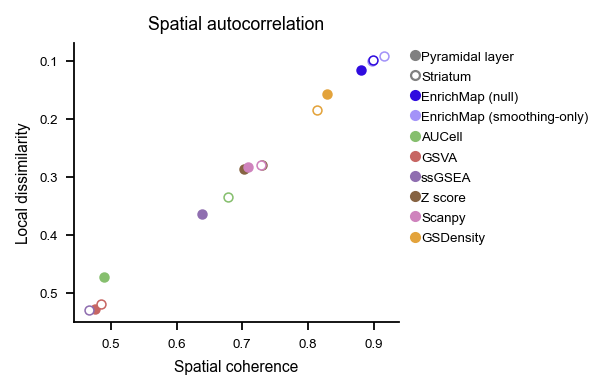

In [13]:
# 9. Extended Data Fig. 2b: Moran's I (x) vs Geary's C (y, inverted so that better is up and right)
fig, ax = plt.subplots(figsize=(2.6, 2.3))
for ct, is_open in zip(regions, (False, True)):
    d = spatial_stats[spatial_stats.region == region_labels[ct]].set_index("method").loc[METHODS]
    for m, r in d.iterrows():
        ax.plot(r["Moran's I"], r["Geary's C"], "o", ms=4, color=colours[m], mfc="white" if is_open else colours[m], mew=0.7)
ax.invert_yaxis()
ax.set_xlabel("Spatial coherence", fontsize=7)
ax.set_ylabel("Local dissimilarity", fontsize=7)
ax.set_title("Spatial autocorrelation", fontsize=8)
ax.tick_params(labelsize=6)
ax.grid(False)
sns.despine(ax=ax)
handles = [Line2D([], [], ls="", marker="o", ms=4, color="0.5", label=region_labels[regions[0]]),
           Line2D([], [], ls="", marker="o", ms=4, color="0.5", mfc="white", label=region_labels[regions[1]])]
handles += [Line2D([], [], ls="", marker="o", ms=4, color=colours[m], label=m) for m in METHODS]
ax.legend(handles=handles, frameon=False, fontsize=6, loc="upper left", bbox_to_anchor=(1.02, 1.0), handletextpad=0.2)
plt.savefig(figure_dir + "ExtendedDataFig2b_morans_i_vs_gearys_c.pdf", bbox_inches="tight")
plt.show()
spatial_stats[["region", "method", "Moran's I", "Geary's C"]].to_csv(
    source_dir + "ExtendedDataFig2b_morans_i_vs_gearys_c.csv", index=False
)

In [14]:
# 10. Sup. Fig. 2d: empirical variograms (as em.pl.variogram_all in 01_visium_platform), raw and divided by the variance
max_lag = np.percentile(pdist(coords), 95)
summary_rows = []
for ct in regions:
    for m in METHODS:
        values = scores[ct][m]
        V = Variogram(coords, values, method="cressie", model="gaussian", verbose=False)
        var = np.var(values)
        for b, gamma in zip(V.bins, V.experimental):
            summary_rows.append({
                "region": region_labels[ct], "method": m, "spatial lag (px)": b, "semivariance": gamma,
                "variance (dashed line)": var, "semivariance / variance": gamma / var,
                "within plotted x range": bool(b <= max_lag),
            })
variograms = pd.DataFrame(summary_rows)

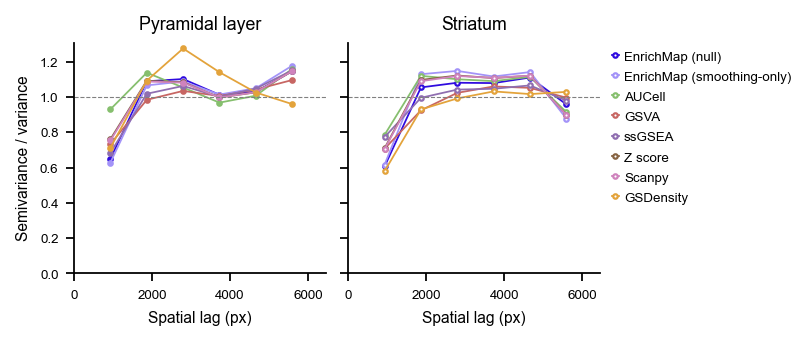

In [15]:
# compact version: semivariance divided by the score variance (unit-free, comparable across methods)
fig, axes = plt.subplots(1, 2, figsize=(5.0, 2.1), sharey=True)
for ax, ct in zip(axes, regions):
    d = variograms[(variograms.region == region_labels[ct]) & variograms["within plotted x range"]]
    for m in METHODS:
        dm = d[d.method == m]
        ax.plot(dm["spatial lag (px)"], dm["semivariance / variance"], "o-", ms=2, lw=0.8, color=colours[m], label=m,
                mfc="white" if ct == regions[1] else colours[m])
    ax.axhline(1, color="0.5", ls="--", lw=0.5)
    ax.set_title(region_labels[ct], fontsize=8)
    ax.set_xlabel("Spatial lag (px)", fontsize=7)
    ax.set_xlim(0, max_lag)
    ax.set_ylim(0, None)
    ax.tick_params(labelsize=6)
    ax.grid(False)
    sns.despine(ax=ax)
axes[0].set_ylabel("Semivariance / variance", fontsize=7)
axes[1].legend(frameon=False, fontsize=6, loc="upper left", bbox_to_anchor=(1.02, 1.0))
plt.tight_layout()
plt.savefig(figure_dir + "ExtendedDataFig2c_variograms.pdf", bbox_inches="tight")
plt.show()
variograms[variograms["within plotted x range"]].to_csv(source_dir + "ExtendedDataFig2c_variograms.csv", index=False)

## Extended Data Fig. 2d: classification of each region vs the rest

The published panel plots F1 at the F1-maximising threshold chosen on the evaluated spots (`17_benchmarking`). As in
`R4_D1_F1_audit`, every method is also evaluated with AUROC, AUPRC and F1 under five rules: oracle, spatial-block CV
(threshold learnt on 4/5 of 25 k-means blocks), prevalence-matched top-k, Otsu (label-free) and median. Fixed rules:
z > 0, z > 1.96 and p_empirical ≤ 0.05 for the null model. Intervals: 95% percentile
intervals of a paired spatial block bootstrap (150 k-means blocks, 1,000 replicates, seed 7; every threshold
re-derived per replicate; the CV rule uses partition r mod 20 in replicate r). Spatial connectivity is the metric of
the published panel (`Spatial coherence` in `17_benchmarking`): Moran's I of the calls at the F1-optimal threshold,
relative to that of the region labels, on the 6-NN graph restricted to the resampled spots in each replicate.

In [16]:
# 11. Sup. Fig. 2e: the 17_benchmarking classification code for every method
clf17 = []
for ct in regions:
    keys = {k.format(ct=ct): m for m, k in method_keys.items()}
    res = _benchmark_pooled(
        adata,
        score_keys=list(keys),
        labels=labels[ct],
        metrics=["auroc", "auprc", "f1", "spatial_coherence", "boundary_f1"],
        n_neighbors=6,
    )
    res = res.pivot(index="method", columns="metric", values="value").reindex(list(keys)).rename(index=keys)
    res = res[["AUROC", "AUPRC", "F1 (optimal)", "Spatial coherence", "Boundary F1"]]
    clf17.append(res.assign(region=region_labels[ct]).reset_index())
clf17 = pd.concat(clf17, ignore_index=True)
print(clf17.set_index(["region", "method"]).round(3).to_string())

metric                                      AUROC  AUPRC  F1 (optimal)  Spatial coherence  Boundary F1
region          method                                                                                
Pyramidal layer EnrichMap (null)            0.994  0.631         0.737              1.000        0.723
                EnrichMap (smoothing-only)  0.996  0.682         0.763              1.000        0.750
                AUCell                      0.986  0.852         0.814              0.858        0.819
                GSVA                        1.000  0.978         0.943              0.985        0.941
                ssGSEA                      0.999  0.909         0.875              1.000        0.882
                Z score                     1.000  0.977         0.953              0.976        0.941
                Scanpy                      1.000  0.975         0.966              1.000        0.953
                GSDensity                   0.997  0.863         0.780   

In [17]:
# 12. Threshold rules of R4_D1_F1_audit for every method, and the fixed rules of the null model
NULL_RULES = ["z > 0", "z > 1.96", "p_empirical <= 0.05"]
FIXED_RULES = [(NULL, r) for r in NULL_RULES]
N_PART = 20
partitions = [spatial_block_partition(coords, n_blocks=25, n_folds=5, seed=k) for k in range(N_PART)]

rows = []
for ct in regions:
    y = labels[ct]
    for m in METHODS:
        s = scores[ct][m]
        met = threshold_rule_metrics(y, s, W=conn, folds=partitions[0])
        cv = [f1_spatial_block_cv(y, s, f) for f in partitions]
        met["F1 (spatial-block CV threshold)"] = float(np.mean(cv))
        met["F1 (spatial-block CV) s.d. over partitions"] = float(np.std(cv, ddof=1))
        f1o, thr = _optimal_f1(y, s)
        pred = s >= thr
        met["n called positive (oracle thr)"] = int(pred.sum())
        met["precision (oracle thr)"] = int((pred & (y == 1)).sum()) / pred.sum()
        met["fraction called positive (Otsu)"] = float((s > otsu_threshold_1d(s)).mean())
        met["fraction called positive (median)"] = float((s > np.median(s)).mean())
        met["F1 (threshold 0)"] = f1_of_calls(y, s > 0)
        met["fraction of region spots > 0"] = float(np.mean(s[y == 1] > 0))
        met["fraction of background spots > 0"] = float(np.mean(s[y == 0] > 0))
        fixed = null_model_rule_calls(s, p_empirical[ct]) if m == NULL else {}
        for rule, calls in fixed.items():
            met[f"F1 ({rule})"] = f1_of_calls(y, calls)
            met[f"n called positive ({rule})"] = int(calls.sum())
            met[f"precision ({rule})"] = float((calls & (y == 1)).sum() / max(calls.sum(), 1))
            met[f"fraction of region spots called ({rule})"] = float(calls[y == 1].mean())
            met[f"fraction of background spots called ({rule})"] = float(calls[y == 0].mean())
        for k, v in met.items():
            rows.append({"region": region_labels[ct], "method": m, "metric": k, "value": float(v)})
clf = pd.DataFrame(rows)

MAIN = [
    "AUROC", "AUPRC", "F1 (oracle threshold)", "F1 (spatial-block CV threshold)",
    "F1 (top-k, prevalence-matched)", "F1 (Otsu, label-free)", "F1 (median threshold)",
]
wide = clf.pivot_table(index=["region", "method"], columns="metric", values="value")
wide = wide.reindex(pd.MultiIndex.from_product([list(region_labels.values()), METHODS], names=["region", "method"]))
print(wide[MAIN].round(3).to_string())
print()
null_cols = [c for c in wide.columns if any(r in c for r in NULL_RULES)]
print(wide.xs(NULL, level="method")[null_cols].T.round(3).to_string())
print()
print(wide[["F1 (threshold 0)", "fraction of region spots > 0", "fraction of background spots > 0"]].round(3).to_string())

metric                                      AUROC  AUPRC  F1 (oracle threshold)  F1 (spatial-block CV threshold)  F1 (top-k, prevalence-matched)  F1 (Otsu, label-free)  F1 (median threshold)
region          method                                                                                                                                                                        
Pyramidal layer EnrichMap (null)            0.994  0.631                  0.737                            0.658                           0.619                  0.515                  0.061
                EnrichMap (smoothing-only)  0.996  0.682                  0.763                            0.713                           0.619                  0.480                  0.061
                AUCell                      0.986  0.852                  0.814                            0.768                           0.786                  0.738                  0.550
                GSVA                        1

In [18]:
# 13. Bootstrap blocks (150 k-means blocks, seed 1) and the number of blocks that carry region spots
N_BLOCKS = 150
N_BOOT = 1000
blocks = spatial_block_partition(coords, n_blocks=N_BLOCKS, n_folds=N_BLOCKS, seed=1)
summary_rows = []
for ct in regions:
    per_block = pd.Series(blocks[labels[ct] == 1]).value_counts()
    summary_rows.append({
        "task": ct, "n blocks": N_BLOCKS, "spots per block (median)": float(np.median(np.bincount(blocks))),
        "region-bearing blocks": len(per_block),
        "region spots per region-bearing block (median)": float(per_block.median()),
        "region spots in the largest block": int(per_block.max()),
    })
block_info = pd.DataFrame(summary_rows)
print(block_info.to_string(index=False))

           task  n blocks  spots per block (median)  region-bearing blocks  region spots per region-bearing block (median)  region spots in the largest block
Pyramidal_layer       150                      18.0                      9                                             5.0                                  6
       Striatum       150                      18.0                     19                                             7.0                                 18


In [19]:
# 14. Paired spatial block bootstrap (1,000 replicates, seed 7)
boot_metrics = {
    "AUROC": roc_auc_score,
    "AUPRC": average_precision_score,
    "F1 (oracle threshold)": lambda y, s: _optimal_f1(y, s)[0],
    "F1 (top-k, prevalence-matched)": f1_prevalence_top_k,
    "F1 (Otsu, label-free)": f1_otsu_threshold,
    "F1 (median threshold)": f1_median_threshold,
}
boot = pd.concat([
    paired_block_bootstrap_rules(
        labels[ct], scores[ct], p_empirical[ct], blocks, partitions, boot_metrics,
        null_method=NULL, n_boot=N_BOOT, seed=7, W=conn,
    ).assign(region=region_labels[ct])
    for ct in regions
], ignore_index=True)
print(f"bootstrap replicates used per region: {boot.groupby('region').replicate.nunique().to_dict()}")

ci = (
    boot.groupby(["region", "method", "metric"])["value"]
    .agg(lo=lambda x: np.quantile(x, 0.025), hi=lambda x: np.quantile(x, 0.975), n_rep="size")
    .reset_index()
)
summary = clf.merge(ci, on=["region", "method", "metric"], how="left")

tab_ci = (
    summary[summary.metric.isin(MAIN)]
    .assign(txt=lambda d: d.apply(format_estimate_ci, axis=1))
    .pivot_table(index=["region", "method"], columns="metric", values="txt", aggfunc="first")
    .reindex(pd.MultiIndex.from_product([list(region_labels.values()), METHODS]))[MAIN]
)
print(tab_ci.to_string())
print()
print(
    summary[
        (summary.method == NULL)
        & summary.metric.isin([f"F1 ({r})" for _, r in FIXED_RULES] + ["F1 (oracle threshold)"])
    ]
    .assign(txt=lambda d: d.apply(format_estimate_ci, axis=1))[["region", "method", "metric", "txt"]].to_string(index=False)
)

bootstrap replicates used per region: {'Pyramidal layer': 1000, 'Striatum': 1000}
metric                                                     AUROC                 AUPRC F1 (oracle threshold) F1 (spatial-block CV threshold) F1 (top-k, prevalence-matched) F1 (Otsu, label-free) F1 (median threshold)
Pyramidal layer EnrichMap (null)            0.994 [0.990, 0.998]  0.631 [0.463, 0.789]  0.737 [0.655, 0.822]            0.658 [0.428, 0.784]           0.619 [0.438, 0.767]  0.515 [0.380, 0.586]  0.061 [0.024, 0.103]
                EnrichMap (smoothing-only)  0.996 [0.992, 0.998]  0.682 [0.516, 0.846]  0.763 [0.687, 0.829]            0.713 [0.435, 0.800]           0.619 [0.458, 0.778]  0.480 [0.342, 0.554]  0.061 [0.024, 0.103]
                AUCell                      0.986 [0.959, 0.999]  0.852 [0.719, 0.942]  0.814 [0.714, 0.903]            0.768 [0.466, 0.863]           0.786 [0.631, 0.878]  0.738 [0.565, 0.839]  0.550 [0.396, 0.655]
                GSVA                        1.000 [0.9

In [20]:
# 15. Paired differences to the null model: positive = comparator higher
piv = boot.pivot_table(index=["region", "metric", "replicate"], columns="method", values="value")
summary_rows = []
for (region, met), d in piv.groupby(level=[0, 1]):
    if met not in MAIN:
        continue
    for m in METHODS[1:]:
        dd = d[m] - d[NULL]
        point = wide.loc[(region, m), met] - wide.loc[(region, NULL), met]
        lo, hi = percentile_interval(dd)
        summary_rows.append({
            "region": region, "metric": met, "method": m, "difference": point, "lo": lo, "hi": hi,
            "CI excludes 0": (lo > 0) or (hi < 0), "share same sign": float(np.mean(np.sign(dd) == np.sign(point))),
        })

dif = pd.DataFrame(summary_rows)
print(
    dif[dif.metric.isin(["AUPRC", "F1 (oracle threshold)", "F1 (top-k, prevalence-matched)"])]
    .assign(txt=lambda d: d.apply(
        lambda r: f"{r.difference:+.3f} [{r.lo:+.3f}, {r.hi:+.3f}] {r['share same sign']:.2f}", axis=1,
    ))
    .pivot_table(index=["region", "method"], columns="metric", values="txt", aggfunc="first")
    .reindex(pd.MultiIndex.from_product([list(region_labels.values()), METHODS[1:]]))
    .to_string()
)

metric                                                             AUPRC         F1 (oracle threshold) F1 (top-k, prevalence-matched)
Pyramidal layer EnrichMap (smoothing-only)  +0.051 [+0.012, +0.118] 1.00  +0.026 [-0.017, +0.069] 0.87   +0.000 [-0.087, +0.108] 0.25
                AUCell                      +0.221 [+0.046, +0.392] 0.99  +0.077 [-0.038, +0.199] 0.92   +0.167 [-0.025, +0.361] 0.94
                GSVA                        +0.347 [+0.187, +0.514] 1.00  +0.206 [+0.140, +0.277] 1.00   +0.286 [+0.158, +0.455] 1.00
                ssGSEA                      +0.278 [+0.126, +0.460] 1.00  +0.138 [+0.061, +0.236] 1.00   +0.190 [+0.030, +0.405] 0.98
                Z score                     +0.346 [+0.189, +0.527] 1.00  +0.217 [+0.121, +0.333] 1.00   +0.333 [+0.152, +0.533] 1.00
                Scanpy                      +0.343 [+0.186, +0.528] 1.00  +0.229 [+0.123, +0.341] 1.00   +0.333 [+0.152, +0.548] 1.00
                GSDensity                   +0.232 [+0.012, +0

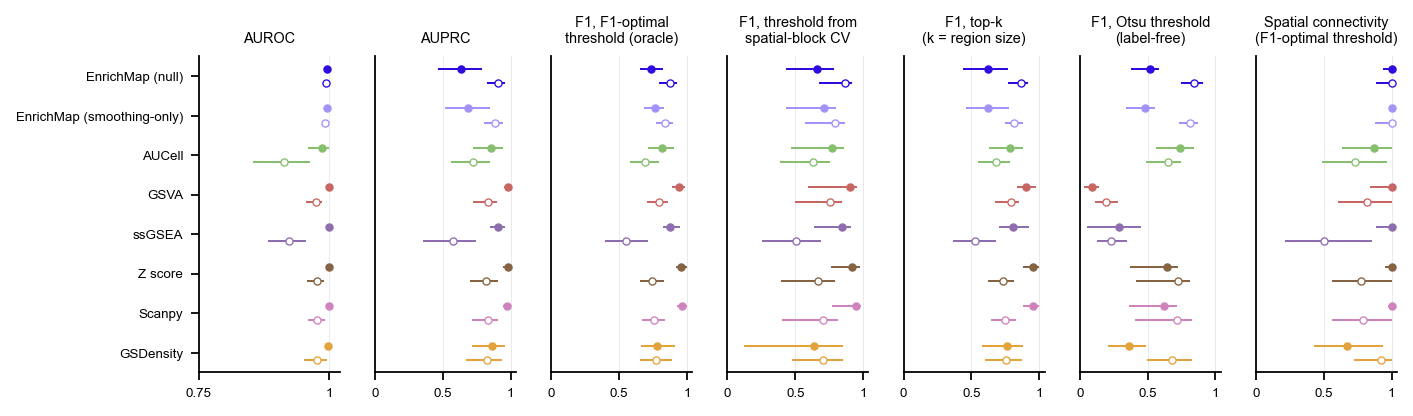

In [21]:
# 16. Extended Data Fig. 2d: one column per metric, estimate and 95% interval (filled: pyramidal layer, open: striatum)
SHOW = [
    ("AUROC", "AUROC"),
    ("AUPRC", "AUPRC"),
    ("F1 (oracle threshold)", "F1, F1-optimal\nthreshold (oracle)"),
    ("F1 (spatial-block CV threshold)", "F1, threshold from\nspatial-block CV"),
    ("F1 (top-k, prevalence-matched)", "F1, top-k\n(k = region size)"),
    ("F1 (Otsu, label-free)", "F1, Otsu threshold\n(label-free)"),
    ("Spatial coherence (oracle thr)", "Spatial connectivity\n(F1-optimal threshold)"),
]
fig, axes = plt.subplots(1, len(SHOW), figsize=(9.6, 2.6))
plotted = []
for j, (ax, (met, title)) in enumerate(zip(axes, SHOW)):
    for i, ct in enumerate(regions):
        region = region_labels[ct]
        d = summary[(summary.region == region) & (summary.metric == met)].set_index("method").reindex(METHODS)
        for k, m in enumerate(METHODS):
            y = k + (0.18 if i else -0.18)
            ax.plot([d.loc[m, "lo"], d.loc[m, "hi"]], [y, y], color=colours[m], lw=0.9, solid_capstyle="butt")
            ax.plot(d.loc[m, "value"], y, "o", ms=3.2, color=colours[m], mfc="white" if i else colours[m], mew=0.6, zorder=3)
            plotted.append({
                "region": region, "metric": met, "method / rule": m, "estimate": d.loc[m, "value"],
                "95% CI lo": d.loc[m, "lo"], "95% CI hi": d.loc[m, "hi"], "n replicates": int(d.loc[m, "n_rep"]),
            })
    format_benchmark_metric_axis(ax, met, len(METHODS))
    if met == "AUROC":
        ax.set_xlim(0.75, 1.02)
        ax.set_xticks([0.75, 1.0])
        ax.set_xticklabels(["0.75", "1"])
    ax.set_yticks(range(len(METHODS)))
    ax.set_yticklabels(METHODS if j == 0 else [], fontsize=6)
    if j:
        ax.tick_params(axis="y", length=0)
    ax.set_title(title, fontsize=6.5)
fig.subplots_adjust(wspace=0.25)
plt.savefig(figure_dir + "ExtendedDataFig2d_classification.pdf", bbox_inches="tight")
plt.show()
pd.DataFrame(plotted).to_csv(source_dir + "ExtendedDataFig2d_classification.csv", index=False)

In [22]:
# 21. Extended Data Fig. 2e: Moran scatter of EnrichMap (null) (as em.pl.morans_correlogram in 01_visium_platform)
F_METHODS = [NULL]
scatter, summary_rows = {}, []
for ct in regions:
    for v in F_METHODS:
        df, moran = moran_scatter_quadrants(scores[ct][v], coords)
        scatter[(ct, v)] = df
        slope, intercept = np.polyfit(df["score"], df["spatial lag"], 1)
        summary_rows.append({
            "region": region_labels[ct], "variant": v, "Moran's I": moran.I, "p (999 permutations)": moran.p_sim,
            "regression slope": slope, "regression intercept": intercept, "score mean (quadrant origin)": df["score"].mean(),
            **{f"share {q}": float(np.mean(df["quadrant"] == q)) for q in ["Co-enriched", "Co-depleted", "Discordant"]},
        })
scatter_stats = pd.DataFrame(summary_rows)

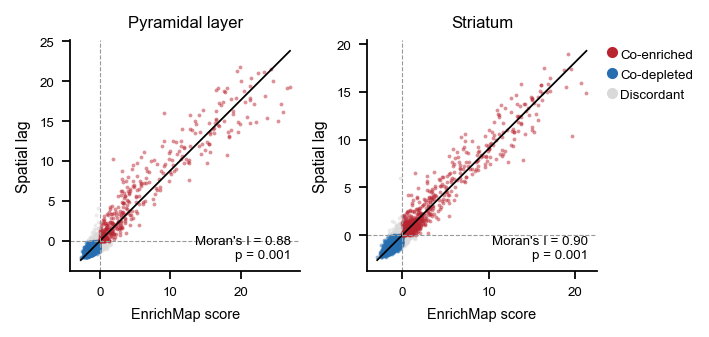

In [23]:
# quadrant colours: the two ends of RdBu_r and grey
cmap = mpl.colormaps["RdBu_r"]
quadrant_colours = {"Discordant": "#d9d9d9", "Co-depleted": cmap(0.12), "Co-enriched": cmap(0.88)}
fig, axes = plt.subplots(1, 2, figsize=(4.4, 2.3))
for ax, ct in zip(axes, regions):
    df = scatter[(ct, NULL)]
    for q, colour in quadrant_colours.items():
        dq = df[df.quadrant == q]
        ax.scatter(dq["score"], dq["spatial lag"], s=3, color=colour, alpha=0.5, linewidths=0)
    st = scatter_stats[(scatter_stats.region == region_labels[ct]) & (scatter_stats.variant == NULL)].iloc[0]
    xs = np.array([df["score"].min(), df["score"].max()])
    ax.plot(xs, st["regression intercept"] + st["regression slope"] * xs, color="black", lw=0.8)
    ax.axvline(st["score mean (quadrant origin)"], color="0.6", lw=0.5, ls="--")
    ax.axhline(st["score mean (quadrant origin)"], color="0.6", lw=0.5, ls="--")
    moran_i, p_sim = st["Moran's I"], st["p (999 permutations)"]
    ax.text(0.96, 0.04, f"Moran's I = {moran_i:.2f}\np = {p_sim:.3f}", transform=ax.transAxes, ha="right",
            va="bottom", fontsize=6)
    ax.set_title(region_labels[ct], fontsize=7.5)
    ax.set_xlabel("EnrichMap score", fontsize=6.5)
    ax.set_ylabel("Spatial lag", fontsize=7)
    ax.tick_params(labelsize=6)
    ax.set_box_aspect(1)
    ax.grid(False)
    sns.despine(ax=ax)
handles = [Line2D([], [], ls="", marker="o", ms=4, color=c, label=q) for q, c in reversed(quadrant_colours.items())]
axes[-1].legend(handles=handles, frameon=False, fontsize=6, loc="upper left", bbox_to_anchor=(1.02, 1.0))
plt.tight_layout()
plt.savefig(figure_dir + "ExtendedDataFig2e_spatial_lag.pdf", bbox_inches="tight")
plt.show()
pd.concat([
    pd.DataFrame({
        "region": region_labels[ct], "variant": NULL, "spot_id": adata.obs_names,
        "score": scatter[(ct, NULL)]["score"].values,
        "spatial lag (mean of 6 nearest spots)": scatter[(ct, NULL)]["spatial lag"].values,
        "quadrant": scatter[(ct, NULL)]["quadrant"].values,
    })
    for ct in regions
], ignore_index=True).to_csv(source_dir + "ExtendedDataFig2e_spatial_lag.csv", index=False)

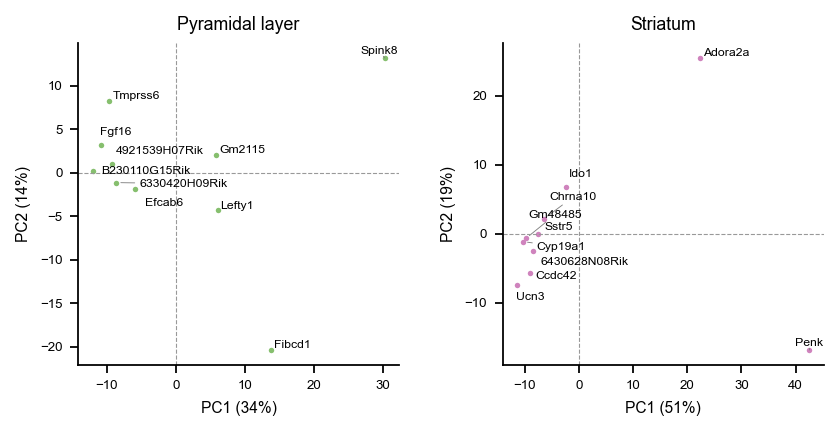

In [24]:
# 22. Extended Data Fig. 2f: PCA of gene contributions (as em.pl.gene_contributions_pca in 01_visium_platform)
pca_rows = []
for ct in regions:
    contrib_dict = adata.uns["gene_contributions"][f"{ct}_smooth"]
    gene_names = list(contrib_dict.keys())
    X = np.vstack([contrib_dict[gene] for gene in gene_names])
    pca = PCA(n_components=2, random_state=0)
    pcs = pca.fit_transform(X)
    norms = np.linalg.norm(X, axis=1)
    for i, g in enumerate(gene_names):
        pca_rows.append({
            "region": region_labels[ct], "gene": g, "PC1": pcs[i, 0], "PC2": pcs[i, 1], "contribution norm": norms[i],
            "PC1 variance explained": pca.explained_variance_ratio_[0],
            "PC2 variance explained": pca.explained_variance_ratio_[1],
        })
pca_genes = pd.DataFrame(pca_rows)

fig, axes = plt.subplots(1, 2, figsize=(5.4, 2.6))
for ax, ct in zip(axes, regions):
    d = pca_genes[pca_genes.region == region_labels[ct]]
    ax.scatter(d["PC1"], d["PC2"], s=6, color={regions[0]: "#86bf6e", regions[1]: "#cf83bd"}[ct], linewidths=0)
    ax.axhline(0, color="0.6", lw=0.5, ls="--")
    ax.axvline(0, color="0.6", lw=0.5, ls="--")
    texts = [ax.text(x, y, g, fontsize=5.5) for x, y, g in zip(d["PC1"], d["PC2"], d["gene"])]
    adjust_text(texts, ax=ax, arrowprops={"arrowstyle": "-", "color": "0.5", "lw": 0.4})
    ax.set_title(region_labels[ct], fontsize=8)
    ax.set_xlabel(f"PC1 ({100 * d['PC1 variance explained'].iloc[0]:.0f}%)", fontsize=7)
    ax.set_ylabel(f"PC2 ({100 * d['PC2 variance explained'].iloc[0]:.0f}%)", fontsize=7)
    ax.tick_params(labelsize=6)
    ax.set_box_aspect(1)
    ax.grid(False)
    sns.despine(ax=ax)
plt.tight_layout()
plt.savefig(figure_dir + "ExtendedDataFig2f_gene_weight_pca.pdf", bbox_inches="tight")
plt.show()
pca_genes.to_csv(source_dir + "ExtendedDataFig2f_gene_weight_pca.csv", index=False)